In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr, linregress
from scipy.optimize import linear_sum_assignment

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics import adjusted_rand_score

PROJECT_DIR = Path.cwd().parent
DATA_DIR = PROJECT_DIR / "data"

IMODULON_DIR = DATA_DIR / "imodulondb"
REGULON_DIR = DATA_DIR / "regulondb"
STRING_DIR = DATA_DIR / "string"

# iModulonDB
GENE_INFO_FILE = IMODULON_DIR / "precise_mg1655-gene_info.csv"
EXPRESSION_FILE = IMODULON_DIR / "precise_mg1655-log_tpm.csv"
SAMPLE_FILE = IMODULON_DIR / "precise_mg1655-sample_table.csv"
TRN_FILE = IMODULON_DIR / "precise_mg1655-trn.csv"

# STRING
STRING_FILE = STRING_DIR / "511145.protein.physical.links.full.v12.5.txt.gz"

# RegulonDB
REGULON_FILE = REGULON_DIR / "NetworkRegulatorGene.tsv"
GENE_PRODUCT_FILE = REGULON_DIR / "GeneProductSet.tsv"

# Load the data
gene_info_df = pd.read_csv(GENE_INFO_FILE)
expression_df = pd.read_csv(EXPRESSION_FILE)
sample_df = pd.read_csv(SAMPLE_FILE)
trn_df = pd.read_csv(TRN_FILE)
string_df = pd.read_csv(
    STRING_FILE,
    sep=r"\s+"
)

#print the shape of the dataframes
datasets = {
    "Gene info": gene_info_df,
    "Expression": expression_df,
    "Sample metadata": sample_df,
    "iModulonDB TRN": trn_df,
    "STRING": string_df
}

for name, df in datasets.items():
    print(f"{name:20s} {df.shape}")

Gene info            (4305, 10)
Expression           (4305, 587)
Sample metadata      (586, 59)
iModulonDB TRN       (10773, 8)
STRING               (93708, 10)


In [3]:
gene_info_df.head()

,gene_id,gene_name,gene_product,start,end,strand,uniprot_id,cog,string_id,gene_synonyms
0,b0001,thrL,thr operon leader peptide,190,255,+,P0AD86,No COG annotation,511145.b0001,NaN
1,b0002,thrA,fused aspartate kinase\/homoserine dehydrogena...,337,2799,+,P00561,Amino acid transport and metabolism,511145.b0002,NaN
2,b0003,thrB,homoserine kinase,2801,3733,+,P00547,Nucleotide transport and metabolism,511145.b0003,NaN
3,b0004,thrC,threonine synthase,3734,5020,+,P00934,Amino acid transport and metabolism,511145.b0004,NaN
4,b0005,yaaX,DUF2502 domain-containing protein YaaX,5234,5530,+,P75616,Function unknown,511145.b0005,NaN


In [4]:
expression_df.head()

,gene_id,pmg_wt_1,pmg_wt_10,pmg_wt_100,pmg_wt_101,pmg_wt_102,pmg_wt_103,pmg_wt_104,pmg_wt_105,pmg_wt_106,...,pmg_wt_90,pmg_wt_91,pmg_wt_92,pmg_wt_93,pmg_wt_94,pmg_wt_95,pmg_wt_96,pmg_wt_97,pmg_wt_98,pmg_wt_99
0,b0001,-0.508210,1.780489,0.722802,1.476414,2.383642,4.112133,3.730746,-0.196990,-0.997967,...,-1.984772,-2.815976,-3.011560,-2.576984,-1.262916,1.347708,1.841094,-0.552674,-1.566595,1.227660
1,b0002,0.182318,-0.197608,-0.822170,-1.536439,-1.543038,-0.771767,-0.773725,1.272620,1.125288,...,-0.262290,-0.522540,-0.558576,-2.008627,-2.383164,-0.117049,-0.147349,-1.088351,-0.983296,-0.554786
2,b0003,0.392437,-0.100001,0.091438,-0.916514,-0.981507,-0.336039,-0.183540,1.444999,1.716814,...,-0.915576,-0.092215,-0.158409,-1.713275,-1.931230,0.119124,0.021417,-0.765254,-0.525073,0.147829
3,b0004,-0.096891,-0.426017,-0.045651,-1.383575,-1.366994,-0.585717,-0.474251,1.103980,1.477590,...,-0.640566,0.171979,0.055813,-1.294275,-1.648703,0.012734,-0.067448,-0.590740,-0.351376,-0.105335
4,b0005,-0.181680,-1.168733,-0.470824,-2.116620,-2.018665,-1.132125,-1.144595,0.609102,0.043054,...,-0.601563,-0.125883,-0.228694,-1.567951,-1.622031,-0.906826,-0.701478,-1.423720,-1.224787,-0.746430


In [5]:
sample_df.head()

,unique_identifier,project_name,condition,replicate_id,reference_condition_identifier,reference_strain,deleted_genes,mutated_genes,overexpressed_genes,perturbed_gene_ids,...,Trace Element Mixture,Run,SRX,n_replicates,passed_pct_reads_mapped,passed_number_replicates,passed_similar_replicates,Antibiotic for selection,enriched_condition,enriched_project
0,pmg_wt_1,pan_fur,WT,1,pmg_wt_445;pmg_wt_446,MG1655,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,[object Object],[object Object]
1,pmg_wt_10,in_house_2,stationary,2,pmg_wt_3;pmg_wt_4,MG1655,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,pmg_wt_100,single_nutrient_perturbation,Uridine_NH4Cl,2,pmg_wt_77;pmg_wt_78,MG1655,NaN,NaN,NaN,NaN,...,Sauer trace element mixture,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,pmg_wt_101,single_nutrient_perturbation,Glucose_L-Ornithine,1,pmg_wt_77;pmg_wt_78,MG1655,NaN,NaN,NaN,NaN,...,Sauer trace element mixture,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,pmg_wt_102,single_nutrient_perturbation,Glucose_L-Ornithine,2,pmg_wt_77;pmg_wt_78,MG1655,NaN,NaN,NaN,NaN,...,Sauer trace element mixture,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
trn_df.head()

,regulator_id,regulator_name,target_id,target_name,effect,magnitude,source,evidence
0,b3243,AaeR,b3240,aaeB,activation,NaN,RegulonDB_TF,0.0
1,b3243,AaeR,b3241,aaeA,activation,NaN,RegulonDB_TF,0.0
2,b3243,AaeR,b3242,aaeX,activation,NaN,RegulonDB_TF,0.0
3,b3255,AccB,b3255,accB,repression,NaN,RegulonDB_TF,0.0
4,b3255,AccB,b3256,accC,repression,NaN,RegulonDB_TF,0.0


In [7]:
string_df.head()

,protein1,protein2,homology,experiments,experiments_transferred,database,database_transferred,textmining,textmining_transferred,combined_score
0,511145.b0002,511145.b0436,0,456,0,0,0,0,0,456
1,511145.b0002,511145.b0473,0,0,174,0,0,0,0,174
2,511145.b0002,511145.b1945,0,0,775,0,0,0,0,775
3,511145.b0002,511145.b2926,0,0,177,0,0,0,0,177
4,511145.b0002,511145.b3347,0,0,338,0,0,0,0,338


In [8]:
# Filter STRING network using different confidence cutoffs
cutoffs = [150, 400, 700, 900]

string_filtered = {}

for cutoff in cutoffs:
    
    df = string_df[
        string_df["combined_score"] >= cutoff
    ].copy()
    
    string_filtered[cutoff] = df
    
    print(
        f"Cutoff {cutoff}: "
        f"{len(df)} interactions"
    )

Cutoff 150: 93708 interactions
Cutoff 400: 57368 interactions
Cutoff 700: 21966 interactions
Cutoff 900: 16244 interactions


In [9]:
# cutoff = 400
# Filter and clean STRING physical interaction network

string_df_filtered = (
    string_df.loc[
        string_df["combined_score"] >= 400, # change the cutoff and just directly run all
        ["protein1", "protein2", "combined_score"]
    ]
    .copy()
)

# Remove the "511145." prefix
string_df_filtered["protein1"] = (
    string_df_filtered["protein1"]
    .str.replace("511145.", "", regex=False)
)

string_df_filtered["protein2"] = (
    string_df_filtered["protein2"]
    .str.replace("511145.", "", regex=False)
)

# Create an undirected protein pair
string_df_filtered[["protein1", "protein2"]] = np.sort(
    string_df_filtered[["protein1", "protein2"]].values,
    axis=1
)

# Remove reciprocal duplicate interactions
string_df_filtered = (
    string_df_filtered
    .drop_duplicates(subset=["protein1", "protein2"])
    .reset_index(drop=True)
)

print("Shape:", string_df_filtered.shape)
string_df_filtered.head()

Shape: (28684, 3)


,protein1,protein2,combined_score
0,b0002,b0436,456
1,b0002,b1945,775
2,b0002,b3940,988
3,b0002,b4024,900
4,b0008,b2464,900


In [10]:
# check if proteins in STRING network are present in the expression_df
string_proteins = set(
    pd.concat([
        string_df_filtered["protein1"],
        string_df_filtered["protein2"]
    ]).unique()
)

# All genes in the expression dataset
expression_genes = set(expression_df["gene_id"])

# Matched and unmatched proteins
matched_proteins = string_proteins & expression_genes
unmatched_proteins = string_proteins - expression_genes

print("STRING proteins:", len(string_proteins))
print("Matched with expression data:", len(matched_proteins))
print("Not matched:", len(unmatched_proteins))
print("Match rate:", len(matched_proteins) / len(string_proteins) * 100, "%")

STRING proteins: 2251
Matched with expression data: 2251
Not matched: 0
Match rate: 100.0 %


In [11]:
# calculation of the degree
protein_degree_df = (
    pd.concat([
        string_df_filtered["protein1"],
        string_df_filtered["protein2"]
    ])
    .value_counts()
    .rename_axis("gene_id")
    .reset_index(name="degree")
)

# Merge degree with expression data
expression_degree_df = expression_df.merge(
    protein_degree_df,
    on="gene_id",
    how="inner"
)

# Move degree directly after gene_id
cols = expression_degree_df.columns.tolist()
cols.remove("degree")
cols.insert(1, "degree")

expression_degree_df = expression_degree_df[cols]

print("Shape:", expression_degree_df.shape)

expression_degree_df.head()

Shape: (2251, 588)


,gene_id,degree,pmg_wt_1,pmg_wt_10,pmg_wt_100,pmg_wt_101,pmg_wt_102,pmg_wt_103,pmg_wt_104,pmg_wt_105,...,pmg_wt_90,pmg_wt_91,pmg_wt_92,pmg_wt_93,pmg_wt_94,pmg_wt_95,pmg_wt_96,pmg_wt_97,pmg_wt_98,pmg_wt_99
0,b0002,4,0.182318,-0.197608,-0.822170,-1.536439,-1.543038,-0.771767,-0.773725,1.272620,...,-0.262290,-0.522540,-0.558576,-2.008627,-2.383164,-0.117049,-0.147349,-1.088351,-0.983296,-0.554786
1,b0008,3,-0.142828,-0.652939,1.365931,0.635379,0.603098,1.111408,1.018034,0.208408,...,0.112757,0.266787,0.186043,-0.297909,-0.259931,0.948028,1.036374,0.993569,1.049810,1.447697
2,b0009,4,-0.142569,-1.392046,1.201413,1.163233,1.136169,1.284574,1.392161,-0.398936,...,-0.681286,0.048930,-0.518525,0.241266,-0.059813,1.183566,1.097356,0.977128,1.603740,1.037476
3,b0014,26,-0.225867,-0.381914,-1.741237,0.828475,0.847240,-0.612834,-0.682152,0.334997,...,-0.905977,0.604662,0.529396,0.309448,-0.247685,-0.510368,-0.607535,-0.021575,0.043524,-1.634491
4,b0015,29,-0.155054,-0.998241,-0.961966,1.158422,1.227208,0.674104,0.584749,0.671190,...,-0.805394,0.729521,0.646539,0.377724,-0.127264,-0.360727,-0.288270,0.638324,0.681661,-0.988455


In [12]:
string_df_filtered.duplicated(
    subset=["protein1", "protein2"]
).sum()

np.int64(0)

In [13]:
# Calculate expression covariance between interacting proteins
# Use gene_id as index for easy expression lookup
expression_lookup = expression_df.set_index("gene_id")

# Calculate covariance for each protein pair
covariance_results = []

for _, row in string_df_filtered.iterrows():
    
    protein1 = row["protein1"]
    protein2 = row["protein2"]
    
    if protein1 in expression_lookup.index and protein2 in expression_lookup.index:
        
        expression1 = expression_lookup.loc[protein1].values.astype(float)
        expression2 = expression_lookup.loc[protein2].values.astype(float)
        
        covariance = np.cov(expression1, expression2)[0, 1]
        
        covariance_results.append({
            "protein1": protein1,
            "protein2": protein2,
            "covariance": covariance
        })

# Convert results to DataFrame
protein_covariance_df = pd.DataFrame(covariance_results)

print("Shape:", protein_covariance_df.shape)
protein_covariance_df.head()

Shape: (28684, 3)


,protein1,protein2,covariance
0,b0002,b0436,0.528515
1,b0002,b1945,0.152263
2,b0002,b3940,0.414198
3,b0002,b4024,1.299114
4,b0008,b2464,0.310870


In [ ]:
# Calculate Pearson and Spearman correlations between interacting protein pairs
# *Pearson correlation*
# measures the strength of a linear relationship, ranging from -1 to 1. 
# positive value: 2 genes tend to increase or decrease together across environments; 
# negative: change in opposite directions. 
# close to 0: little linear association. 
# *Spearman correlation*
# measures the strength of a monotonic relationship, ranging from -1 to 1.
# close to 0: little monotonic association.

# Use gene_id as index for easy expression lookup
expression_lookup = expression_df.set_index("gene_id")

correlation_results = []

for _, row in string_df_filtered.iterrows():

    protein1 = row["protein1"]
    protein2 = row["protein2"]

    # Only use pairs where both proteins have expression data
    if protein1 in expression_lookup.index and protein2 in expression_lookup.index:

        expression1 = expression_lookup.loc[protein1].values.astype(float)
        expression2 = expression_lookup.loc[protein2].values.astype(float)

        # Pearson correlation
        pearson_r, _ = pearsonr(expression1, expression2)

        # Spearman correlation
        spearman_rho, _ = spearmanr(expression1, expression2)

        correlation_results.append({
            "protein1": protein1,
            "protein2": protein2,
            "pearson_correlation": pearson_r,
            "spearman_correlation": spearman_rho
        })

# Create pair-level correlation dataset
protein_correlation_df = pd.DataFrame(correlation_results)

print("Shape:", protein_correlation_df.shape)
protein_correlation_df.head()

Shape: (28684, 4)


,protein1,protein2,pearson_correlation,spearman_correlation
0,b0002,b0436,0.395852,0.034371
1,b0002,b1945,0.052565,-0.020246
2,b0002,b3940,0.413680,0.302101
3,b0002,b4024,0.680709,0.428736
4,b0008,b2464,0.205923,0.236768


In [15]:
# Calculate mean partner correlations for each protein and combine with degree
# Calculate mean Pearson and Spearman correlation for each protein
mean_correlation_df = (
    protein_correlation_df
    .groupby("protein1")
    .agg(
        mean_pearson_correlation=("pearson_correlation", "mean"),
        mean_spearman_correlation=("spearman_correlation", "mean")
    )
    .reset_index()
    .rename(columns={"protein1": "gene_id"})
)

# Combine with protein degree
protein_summary_df = protein_degree_df.merge(
    mean_correlation_df,
    on="gene_id",
    how="inner"
)

print("Shape:", protein_summary_df.shape)
protein_summary_df.head()

Shape: (1750, 4)


,gene_id,degree,mean_pearson_correlation,mean_spearman_correlation
0,b2417,197,0.032182,-0.059739
1,b3751,197,0.222753,0.149543
2,b3725,196,0.139719,0.142217
3,b1117,191,0.204123,0.215596
4,b4035,190,-0.127811,-0.184662


Mean Pearson correlation
Pearson r     = -0.1169 (p = 9.373e-07)
Spearman rho  = -0.1008 (p = 2.410e-05)
R²            = 0.0137



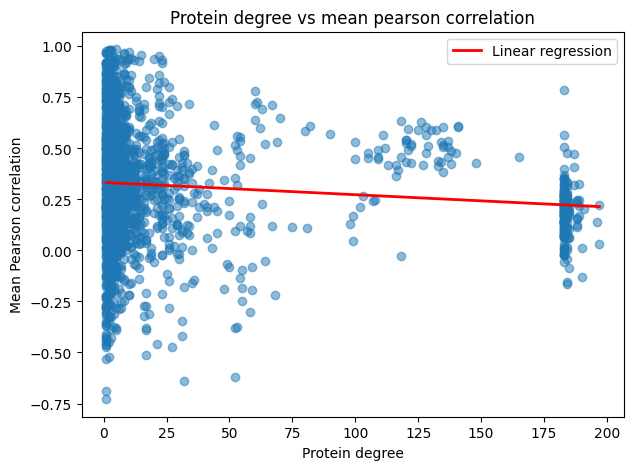

Mean Spearman correlation
Pearson r     = -0.0839 (p = 4.439e-04)
Spearman rho  = -0.0751 (p = 1.661e-03)
R²            = 0.0070



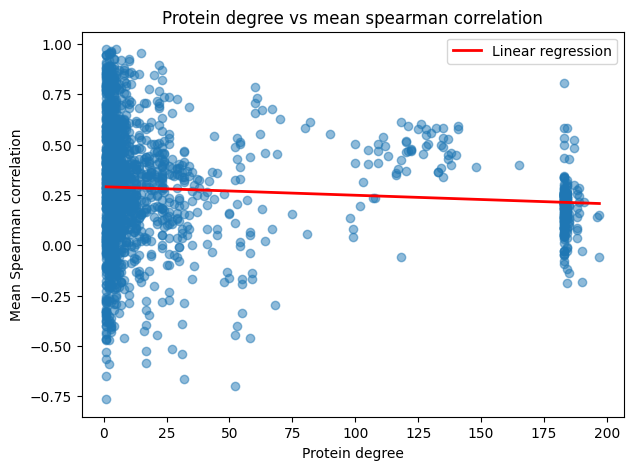

In [ ]:
# Degree vs mean partner correlation
# Pearson and Spearman expression measures

# Variables to analyse
correlation_columns = [
    ("mean_pearson_correlation", "Mean Pearson correlation"),
    ("mean_spearman_correlation", "Mean Spearman correlation")
]

for column, ylabel in correlation_columns:

    x = protein_summary_df["degree"]
    y = protein_summary_df[column]

    # Association between degree and mean partner correlation
    pearson_r, pearson_p = pearsonr(x, y)
    spearman_rho, spearman_p = spearmanr(x, y)

    # Linear regression
    regression = linregress(x, y)
    r_squared = regression.rvalue ** 2

    # Print statistics
    print(f"{ylabel}")
    print(f"Pearson r     = {pearson_r:.4f} (p = {pearson_p:.3e})")
    print(f"Spearman rho  = {spearman_rho:.4f} (p = {spearman_p:.3e})")
    print(f"R²            = {r_squared:.4f}")
    print()

    # Plot
    plt.figure(figsize=(7, 5))

    plt.scatter(
        x,
        y,
        alpha=0.5
    )

    # Regression line
    x_line = np.linspace(x.min(), x.max(), 200)
    y_line = regression.intercept + regression.slope * x_line

    plt.plot(
        x_line,
        y_line,
        color="red",
        linewidth=2,
        label="Linear regression"
    )

    plt.xlabel("Protein degree")
    plt.ylabel(ylabel)
    plt.title(f"Protein degree vs {ylabel.lower()}")
    plt.legend()
    plt.show()
    
# 1. Proteins with low degree show a very wide range of mean correlations, 
# including strongly positive, near-zero, and negative values. 
# This indicates that proteins with only a few interaction partners can have 
# very different levels of expression coordination with their partners.
# 2. At intermediate degrees, several groups of proteins appear to cluster 
# around relatively high mean correlations (approximately 0.35–0.5). 

In [17]:
# Build protein-partner table from the undirected STRING network
protein_partner_df = pd.concat([
    string_df_filtered[
        ["protein1", "protein2"]
    ].rename(columns={
        "protein1": "protein",
        "protein2": "partner"
    }),

    string_df_filtered[
        ["protein1", "protein2"]
    ].rename(columns={
        "protein2": "protein",
        "protein1": "partner"
    })
], ignore_index=True)

# Safety check: one unique partner per protein
protein_partner_df = protein_partner_df.drop_duplicates(
    subset=["protein", "partner"]
)

# Add COG function of each partner
protein_partner_function_df = protein_partner_df.merge(
    gene_info_df[
        ["gene_id", "gene_name", "gene_product", "cog"]
    ],
    left_on="partner",
    right_on="gene_id",
    how="left"
)

protein_partner_function_df = (
    protein_partner_function_df
    .drop(columns="gene_id")
    .rename(columns={
        "gene_name": "partner_gene_name",
        "gene_product": "partner_gene_product",
        "cog": "cog"
    })
)

protein_partner_function_df.head(10)

,protein,partner,partner_gene_name,partner_gene_product,cog
0,b0002,b0436,tig,trigger factor,"Cell cycle control, cell division, chromosome ..."
1,b0002,b1945,fliM,flagellar motor switch protein FliM,Cell motility
2,b0002,b3940,metL,fused aspartate kinase\/homoserine dehydrogena...,Amino acid transport and metabolism
3,b0002,b4024,lysC,aspartate kinase III,Amino acid transport and metabolism
4,b0008,b2464,talA,transaldolase A,Nucleotide transport and metabolism
5,b0008,b2465,tktB,transketolase 2,Carbohydrate transport and metabolism
6,b0008,b3781,trxA,thioredoxin 1,"Post-translational modification, protein turno..."
7,b0009,b0782,moaB,protein MoaB,Coenzyme transport and metabolism
8,b0009,b0827,moeA,molybdopterin molybdotransferase,Coenzyme transport and metabolism
9,b0009,b1727,hxpB,hexitol phosphatase B,Function unknown


In [18]:
# Create pair key for matching protein pairs
protein_partner_function_df["pair_key"] = (
    protein_partner_function_df[["protein", "partner"]]
    .apply(lambda x: tuple(sorted(x)), axis=1)
)

protein_correlation_df["pair_key"] = (
    protein_correlation_df[["protein1", "protein2"]]
    .apply(lambda x: tuple(sorted(x)), axis=1)
)


# Add Pearson and Spearman correlation to each protein-partner pair
functional_pair_df = protein_partner_function_df.merge(
    protein_correlation_df[
        ["pair_key", "pearson_correlation", "spearman_correlation"]
    ],
    on="pair_key",
    how="left"
)


# Summarize for each protein × partner function
functional_summary_df = (
    functional_pair_df
    .groupby(["protein", "cog"])
    .agg(
        cog_degree=("partner", "nunique"),
        mean_pearson=("pearson_correlation", "mean"),
        mean_spearman=("spearman_correlation", "mean")
    )
    .reset_index()
)

functional_summary_df.head()

,protein,cog,cog_degree,mean_pearson,mean_spearman
0,b0002,Amino acid transport and metabolism,2,0.547195,0.365418
1,b0002,"Cell cycle control, cell division, chromosome ...",1,0.395852,0.034371
2,b0002,Cell motility,1,0.052565,-0.020246
3,b0008,Carbohydrate transport and metabolism,1,0.228100,0.243342
4,b0008,Nucleotide transport and metabolism,1,0.205923,0.236768


In [ ]:
function_results = []

for function_name, group in functional_summary_df.groupby("cog"):

    # Need at least several proteins
    if len(group) < 10:
        continue

    # Skip functions where functional degree is constant
    if group["cog_degree"].nunique() < 2:
        continue

    rho, p_value = spearmanr(
        group["cog_degree"],
        group["mean_spearman"]
    )

    function_results.append({
        "cog": function_name,
        "n_proteins": len(group),
        "spearman_rho": rho,
        "p_value": p_value
    })


function_results_df = pd.DataFrame(function_results)
function_results_df.sort_values("spearman_rho")

,cog,n_proteins,spearman_rho,p_value
17,Signal transduction mechanisms,194,-0.212266,2.964866e-03
1,Carbohydrate transport and metabolism,431,-0.188887,7.960868e-05
4,Cell wall\/membrane\/envelope biogenesis,445,-0.109013,2.144652e-02
9,Inorganic ion transport and metabolism,440,-0.102305,3.191311e-02
16,"Secondary metabolites biosynthesis, transport,...",43,-0.085173,5.870960e-01
8,Function unknown,763,-0.071540,4.822255e-02
0,Amino acid transport and metabolism,500,-0.064276,1.512464e-01
10,"Intracellular trafficking, secretion, and vesi...",354,-0.032104,5.471348e-01
6,Defense mechanisms,244,-0.021349,7.400368e-01
18,Transcription,505,0.022426,6.151217e-01


In [22]:
# Cell motility only

function_name = "Cell motility"

function_test_df = functional_summary_df[
    functional_summary_df["cog"] == function_name
].copy()

print("Number of proteins:", len(function_test_df))
display(
    function_test_df
    .sort_values("cog_degree", ascending=False)
    .head(30)
)

Number of proteins: 153


,protein,cog,cog_degree,mean_pearson,mean_spearman
2969,b1880,Cell motility,22,0.856632,0.742179
3121,b1949,Cell motility,22,0.907156,0.811051
3123,b1950,Cell motility,21,0.879354,0.759070
1821,b1076,Cell motility,21,0.927912,0.842305
3119,b1948,Cell motility,21,0.938680,0.849749
3113,b1946,Cell motility,21,0.941335,0.841012
2973,b1882,Cell motility,19,0.841943,0.602796
3090,b1938,Cell motility,19,0.941325,0.847839
3109,b1945,Cell motility,19,0.946468,0.871852
1840,b1080,Cell motility,18,0.942158,0.867143


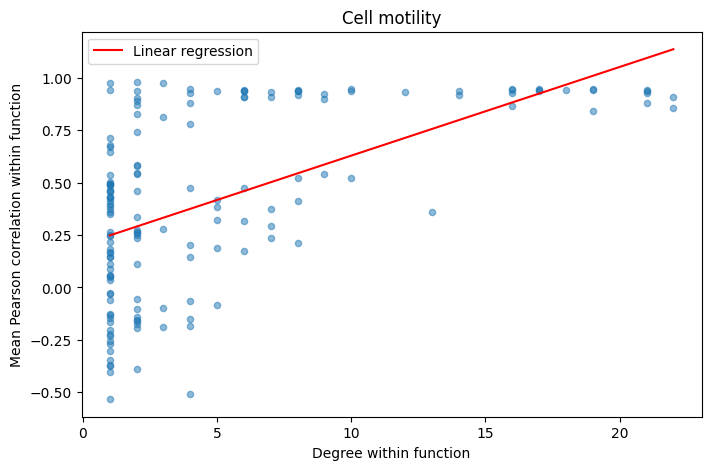

Pearson r: 0.5581065536207711 p = 6.62996180392721e-14
Spearman rho: 0.5606301796118227 p = 4.840599909707756e-14


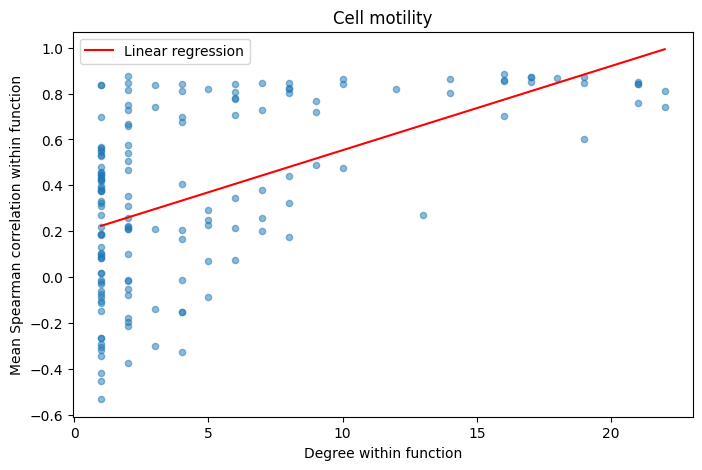

Pearson r: 0.544064809216094 p = 3.6391850976288543e-13
Spearman rho: 0.5444773911907245 p = 3.465483842837507e-13


In [ ]:
# Pearson

x = function_test_df["cog_degree"]
y = function_test_df["mean_pearson"]

r, p_r = pearsonr(x, y)
rho, p_rho = spearmanr(x, y)

coef = np.polyfit(x, y, 1)
line = np.poly1d(coef)

plt.figure(figsize=(8, 5))

plt.scatter(
    x,
    y,
    alpha=0.5,
    s=20
)

plt.plot(
    np.sort(x),
    line(np.sort(x)),
    color="red",
    label="Linear regression"
)

plt.xlabel("Degree within function")
plt.ylabel("Mean Pearson correlation within function")
plt.title("Cell motility")
plt.legend()
plt.show()
print("Pearson r:", r, "p =", p_r)
print("Spearman rho:", rho, "p =", p_rho)


# Spearman
x = function_test_df["cog_degree"]
y = function_test_df["mean_spearman"]

r, p_r = pearsonr(x, y)
rho, p_rho = spearmanr(x, y)

coef = np.polyfit(x, y, 1)
line = np.poly1d(coef)

plt.figure(figsize=(8, 5))

plt.scatter(
    x,
    y,
    alpha=0.5,
    s=20
)

plt.plot(
    np.sort(x),
    line(np.sort(x)),
    color="red",
    label="Linear regression"
)

plt.xlabel("Degree within function")
plt.ylabel("Mean Spearman correlation within function")
plt.title("Cell motility")
plt.legend()
plt.show()
print("Pearson r:", r, "p =", p_r)
print("Spearman rho:", rho, "p =", p_rho)

In [ ]:
# Examine individual partner correlations within Cell motility to check the detail, instead of mean correlations. 
# This will allow us to see if there are any outliers or specific protein-partner pairs that are driving the overall correlation.

function_name = "Cell motility"

# 1. Select protein-partner pairs where the partner belongs to Cell motility
cell_motility_pairs = protein_partner_function_df[
    protein_partner_function_df["cog"] == function_name
][["protein", "partner"]].copy()


# 2. Create undirected pair keys
# This allows A-B and B-A to be treated as the same interaction
cell_motility_pairs["pair_key"] = cell_motility_pairs[
    ["protein", "partner"]
].apply(lambda x: tuple(sorted(x)), axis=1)

protein_correlation_temp = protein_correlation_df.copy()

protein_correlation_temp["pair_key"] = protein_correlation_temp[
    ["protein1", "protein2"]
].apply(lambda x: tuple(sorted(x)), axis=1)


# 3. Add the individual Pearson and Spearman correlations
cell_motility_individual_df = cell_motility_pairs.merge(
    protein_correlation_temp[
        ["pair_key", "pearson_correlation", "spearman_correlation"]
    ],
    on="pair_key",
    how="left"
)


# 4. Calculate functional degree for each protein
# Number of Cell motility partners connected to that protein
functional_degree = (
    cell_motility_individual_df
    .groupby("protein")["partner"]
    .nunique()
    .rename("function_degree")
)

cell_motility_individual_df = cell_motility_individual_df.merge(
    functional_degree,
    on="protein",
    how="left"
)

# 5. Remove missing correlations（though there shouldn't be any, but just in case）
cell_motility_individual_df = (
    cell_motility_individual_df
    .dropna(subset=["spearman_correlation"])
)

# Check the resulting table
print("Number of interactions:", len(cell_motility_individual_df))
print("Number of proteins:", cell_motility_individual_df["protein"].nunique())
cell_motility_individual_df.head(15)

Number of interactions: 767
Number of proteins: 153


,protein,partner,pair_key,pearson_correlation,spearman_correlation,function_degree
0,b0002,b1945,"(b0002, b1945)",0.052565,-0.020246,1
1,b0047,b1078,"(b0047, b1078)",-0.370329,-0.416372,1
2,b0054,b4558,"(b0054, b4558)",0.678886,0.552750,1
3,b0081,b1077,"(b0081, b1077)",-0.304237,-0.293350,1
4,b0106,b3394,"(b0106, b3394)",0.503105,0.445447,1
5,b0107,b3394,"(b0107, b3394)",0.182497,0.083383,1
6,b0121,b1945,"(b0121, b1945)",0.245981,0.377486,1
7,b0139,b0939,"(b0139, b0939)",0.385732,0.232356,6
8,b0139,b0940,"(b0139, b0940)",0.698676,0.554785,6
9,b0139,b2109,"(b0139, b2109)",0.640873,0.447477,6


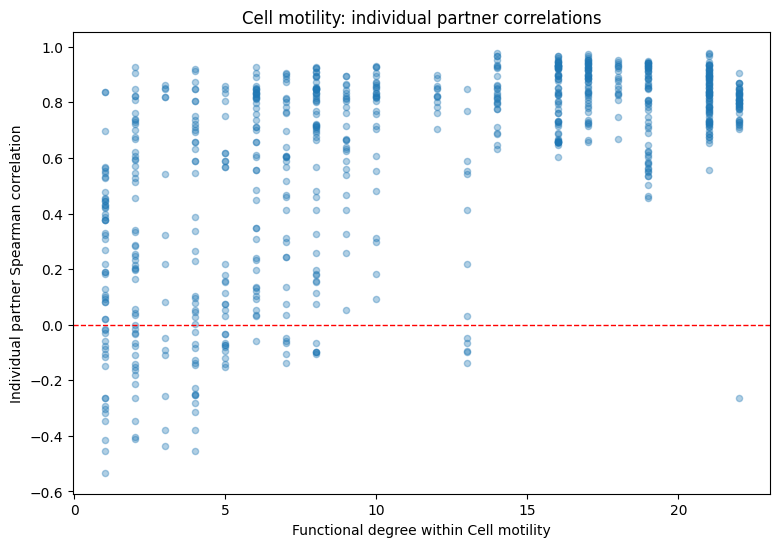

In [27]:
# Plot individual partner correlations against functional degree
plt.figure(figsize=(9, 6))

plt.scatter(
    cell_motility_individual_df["function_degree"],
    cell_motility_individual_df["spearman_correlation"],
    alpha=0.35,
    s=20
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    linewidth=1
)

plt.xlabel("Functional degree within Cell motility")
plt.ylabel("Individual partner Spearman correlation")
plt.title("Cell motility: individual partner correlations")
plt.show()

In [35]:
# Find proteins with high functional degree in Cell motility
high_degree_cell_motility = (
    cell_motility_individual_df[
        cell_motility_individual_df["function_degree"] >= 5
    ][["protein", "function_degree"]]
    .drop_duplicates()
    .sort_values("function_degree", ascending=False)
)

# Add gene annotation
high_degree_cell_motility = high_degree_cell_motility.merge(
    gene_info_df[
        ["gene_id", "gene_name", "gene_product", "cog"]
    ],
    left_on="protein",
    right_on="gene_id",
    how="left"
)

high_degree_cell_motility[
    ["protein", "gene_name", "gene_product", "function_degree"]
]

# Most high-functional-degree proteins in the Cell motility group are 
# components of the flagellar machinery, such as FlhB, FliQ, FliR, FliP, FlgE, and FliM.
# These proteins participate in the construction and operation of the same complex molecular machine. 

# Their strongly coordinated expression therefore supports our interpretation that 
# high functional degree can reflect coordinated regulation 
# among proteins working together in a shared molecular structure.

,protein,gene_name,gene_product,function_degree
0,b1880,flhB,flagellar biosynthesis protein FlhB,22
1,b1949,fliQ,flagellar biosynthesis protein FliQ,22
2,b1076,flgE,flagellar hook protein FlgE,21
3,b1950,fliR,flagellar biosynthesis protein FliR,21
4,b1946,fliN,flagellar motor switch protein FliN,21
5,b1948,fliP,flagellar biosynthesis protein FliP,21
6,b1945,fliM,flagellar motor switch protein FliM,19
7,b1938,fliF,flagellar basal-body MS-ring and collar protein,19
8,b1882,cheY,chemotaxis protein CheY,19
9,b1080,flgI,flagellar P-ring protein,18


Selected function:
'Defense mechanisms'

Number of proteins: 244
Spearman rho = -0.0213
p-value = 7.4004e-01


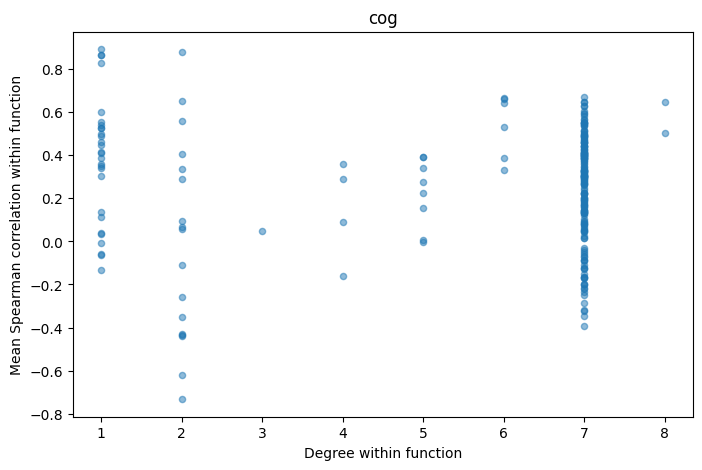

In [ ]:
# Select the function with Spearman rho closest to zero
selected_row = function_results_df.loc[
    function_results_df["spearman_rho"].abs().idxmin()
]

function_name = selected_row["cog"]

print("Selected function:")
print(repr(function_name))
print()

function_test_df = functional_summary_df[
    functional_summary_df["cog"] == function_name
]

print("Number of proteins:", len(function_test_df))

rho, p_value = spearmanr(
    function_test_df["function_degree"],
    function_test_df["mean_spearman"]
)

print(f"Spearman rho = {rho:.4f}")
print(f"p-value = {p_value:.4e}")


plt.figure(figsize=(8, 5))

plt.scatter(
    function_test_df["function_degree"],
    function_test_df["mean_spearman"],
    alpha=0.5,
    s=20
)

plt.xlabel("Degree within function")
plt.ylabel("Mean Spearman correlation within function")
plt.title("cog")
plt.show()

In [ ]:
# Examine individual partner correlations within Defense mechanisms

function_name = "Defense mechanisms"

# 1. Select protein-partner pairs where the partner belongs to Defense mechanisms
defense_pairs = protein_partner_function_df[
    protein_partner_function_df["cog"] == function_name
][["protein", "partner"]].copy()

# 2. Create undirected pair keys
# A-B and B-A are treated as the same interaction
defense_pairs["pair_key"] = defense_pairs[
    ["protein", "partner"]
].apply(lambda x: tuple(sorted(x)), axis=1)

protein_correlation_temp = protein_correlation_df.copy()

protein_correlation_temp["pair_key"] = protein_correlation_temp[
    ["protein1", "protein2"]
].apply(lambda x: tuple(sorted(x)), axis=1)

# 3. Add individual Pearson and Spearman correlations
defense_individual_df = defense_pairs.merge(
    protein_correlation_temp[
        ["pair_key", "pearson_correlation", "spearman_correlation"]
    ],
    on="pair_key",
    how="left"
)

# 4. Calculate functional degree for each protein
# Number of Defense mechanisms partners connected to that protein
functional_degree = (
    defense_individual_df
    .groupby("protein")["partner"]
    .nunique()
    .rename("function_degree")
)

defense_individual_df = defense_individual_df.merge(
    functional_degree,
    on="protein",
    how="left"
)

# 5. Remove missing correlations
defense_individual_df = (
    defense_individual_df
    .dropna(subset=["spearman_correlation"])
)

print("Number of interactions:", len(defense_individual_df))
print(
    "Number of proteins:",
    defense_individual_df["protein"].nunique()
)

defense_individual_df.head(15)

Number of interactions: 1419
Number of proteins: 244


,protein,partner,pair_key,pearson_correlation,spearman_correlation,function_degree
0,b0041,b0794,"(b0041, b0794)",-0.053680,-0.132927,1
1,b0066,b0792,"(b0066, b0792)",0.397758,0.240490,7
2,b0066,b0793,"(b0066, b0793)",0.445755,0.373930,7
3,b0066,b0794,"(b0066, b0794)",0.449320,0.377384,7
4,b0066,b0914,"(b0066, b0914)",0.503765,0.424278,7
5,b0066,b1117,"(b0066, b1117)",0.667870,0.594377,7
6,b0066,b1292,"(b0066, b1292)",0.418145,0.379352,7
7,b0066,b1293,"(b0066, b1293)",0.425660,0.320586,7
8,b0067,b0792,"(b0067, b0792)",0.446857,0.396153,7
9,b0067,b0793,"(b0067, b0793)",0.530481,0.529264,7


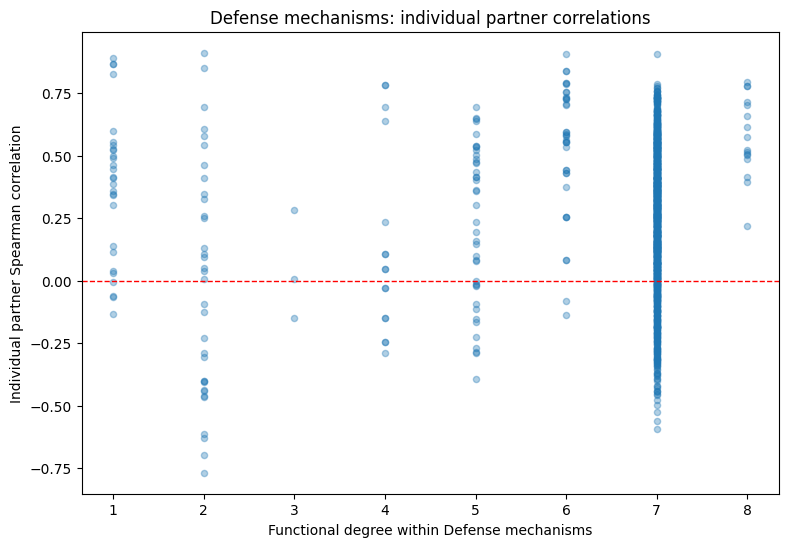

In [ ]:
# Plot individual partner correlations against functional degree

plt.figure(figsize=(9, 6))

plt.scatter(
    defense_individual_df["function_degree"],
    defense_individual_df["spearman_correlation"],
    alpha=0.35,
    s=20
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    linewidth=1
)

plt.xlabel("Functional degree within Defense mechanisms")
plt.ylabel("Individual partner Spearman correlation")
plt.title("Defense mechanisms: individual partner correlations")

plt.show()

In [ ]:
# Number of proteins at each functional degree
defense_degree_counts = (
    defense_individual_df[
        ["protein", "function_degree"]
    ]
    .drop_duplicates()
    ["function_degree"]
    .value_counts()
    .sort_index()
)

print(defense_degree_counts)

function_degree
1     28
2     17
3      1
4      4
5      8
6      6
7    178
8      2
Name: count, dtype: int64


In [ ]:
# Get one row per protein
defense_protein_degree = (
    defense_individual_df[
        ["protein", "function_degree"]
    ]
    .drop_duplicates()
    .sort_values(
        "function_degree",
        ascending=False
    )
)

high_degree_defense = (
    defense_individual_df[
        defense_individual_df["function_degree"] >= 6
    ][["protein", "function_degree"]]
    .drop_duplicates()
    .sort_values("function_degree", ascending=False)
)

# Add gene annotation
high_degree_defense = high_degree_defense.merge(
    gene_info_df[
        ["gene_id", "gene_name", "gene_product", "cog"]
    ],
    left_on="protein",
    right_on="gene_id",
    how="left"
)

display(
    high_degree_defense[
        ["protein", "gene_name", "gene_product", "function_degree"]
    ]
    .sort_values("function_degree", ascending=False)
    .head(20)
)

,protein,gene_name,gene_product,function_degree
0,b1118,lolE,lipoprotein release complex - inner membrane s...,8
1,b1116,lolC,lipoprotein release complex - inner membrane s...,8
2,b0068,thiB,thiamine ABC transporter periplasmic binding p...,7
3,b0151,fhuC,iron(III) hydroxamate ABC transporter ATP bind...,7
4,b0152,fhuD,iron(III) hydroxamate ABC transporter periplas...,7
5,b0153,fhuB,iron(III) hydroxamate ABC transporter membrane...,7
6,b0158,btuF,vitamin B12 ABC transporter periplasmic bindin...,7
7,b0197,metQ,L-methionine\/D-methionine ABC transporter mem...,7
8,b0066,thiQ,thiamine ABC transporter ATP binding subunit,7
9,b0067,thiP,thiamine ABC transporter membrane subunit,7


In [ ]:
# unsupervised learning: build a feature vector for each protein

# Build one feature vector for each protein
defense_features = (
    defense_individual_df
    .groupby("protein")
    .agg(
        function_degree=("function_degree", "first"),

        # central tendency of partner correlations
        mean_spearman=("spearman_correlation", "mean"),
        median_spearman=("spearman_correlation", "median"),

        # heterogeneity of partner correlations
        sd_spearman=("spearman_correlation", "std"),

        # minimum and maximum correlation
        min_spearman=("spearman_correlation", "min"),
        max_spearman=("spearman_correlation", "max"),

        # number of partners
        n_partners=("partner", "nunique")
    )
    .reset_index()
)

# Fraction of strongly positive / negative correlations
extra_features = (
    defense_individual_df
    .groupby("protein")["spearman_correlation"]
    .agg(
        fraction_positive=lambda x: (x > 0.5).mean(),
        fraction_negative=lambda x: (x < 0).mean()
    )
    .reset_index()
)

# Merge
defense_features = defense_features.merge(
    extra_features,
    on="protein",
    how="left"
)

display(defense_features.head(20))
print("Number of proteins:", len(defense_features))

,protein,function_degree,mean_spearman,median_spearman,sd_spearman,min_spearman,max_spearman,n_partners,fraction_positive,fraction_negative
0,b0041,1,-0.132927,-0.132927,NaN,-0.132927,-0.132927,1,0.000000,1.000000
1,b0066,7,0.387199,0.377384,0.108468,0.240490,0.594377,7,0.142857,0.000000
2,b0067,7,0.547503,0.552031,0.080100,0.396153,0.662594,7,0.857143,0.000000
3,b0068,7,0.246640,0.194952,0.127327,0.126576,0.458637,7,0.000000,0.000000
4,b0128,1,0.541515,0.541515,NaN,0.541515,0.541515,1,1.000000,0.000000
5,b0151,7,0.177595,0.182440,0.085037,0.067061,0.334888,7,0.000000,0.000000
6,b0152,7,0.265943,0.228469,0.120504,0.136850,0.480842,7,0.000000,0.000000
7,b0153,7,0.131187,0.094694,0.084102,0.068674,0.290715,7,0.000000,0.000000
8,b0158,7,0.333535,0.299978,0.112872,0.240371,0.568883,7,0.142857,0.000000
9,b0196,1,0.497881,0.497881,NaN,0.497881,0.497881,1,0.000000,0.000000


Number of proteins: 244


In [ ]:
feature_cols = [
    "function_degree",
    "mean_spearman",
    "median_spearman",
    "sd_spearman",
    "fraction_positive",
    "fraction_negative"
]

# Select features for PCA
pca_df = defense_features[
    ["protein"] + feature_cols
].copy()

# For proteins with only one partner, SD cannot be calculated.
# Set SD = 0 because there is no observed variation among partners.
pca_df["sd_spearman"] = pca_df["sd_spearman"].fillna(0)

# Check missing values
print(pca_df[feature_cols].isna().sum())

display(pca_df.head(20))

function_degree      0
mean_spearman        0
median_spearman      0
sd_spearman          0
fraction_positive    0
fraction_negative    0
dtype: int64


,protein,function_degree,mean_spearman,median_spearman,sd_spearman,fraction_positive,fraction_negative
0,b0041,1,-0.132927,-0.132927,0.000000,0.000000,1.000000
1,b0066,7,0.387199,0.377384,0.108468,0.142857,0.000000
2,b0067,7,0.547503,0.552031,0.080100,0.857143,0.000000
3,b0068,7,0.246640,0.194952,0.127327,0.000000,0.000000
4,b0128,1,0.541515,0.541515,0.000000,1.000000,0.000000
5,b0151,7,0.177595,0.182440,0.085037,0.000000,0.000000
6,b0152,7,0.265943,0.228469,0.120504,0.000000,0.000000
7,b0153,7,0.131187,0.094694,0.084102,0.000000,0.000000
8,b0158,7,0.333535,0.299978,0.112872,0.142857,0.000000
9,b0196,1,0.497881,0.497881,0.000000,0.000000,0.000000


In [ ]:
feature_cols = [
    "function_degree",
    "mean_spearman",
    "median_spearman",
    "sd_spearman",
    "fraction_positive",
    "fraction_negative"
]

X = pca_df[feature_cols]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Original shape:", X.shape)
print("Scaled shape:", X_scaled.shape)

X_scaled[:5]

Original shape: (244, 6)
Scaled shape: (244, 6)


array([[-2.18728565, -1.37934195, -1.34564638, -1.36004499, -0.68520777,
         2.2741967 ],
       [ 0.53797919,  0.47894188,  0.34182095, -0.0962472 , -0.26982716,
        -0.5813319 ],
       [ 0.53797919,  1.05166558,  0.919335  , -0.42677584,  1.8070759 ,
        -0.5813319 ],
       [ 0.53797919, -0.02324423, -0.26143521,  0.12348258, -0.68520777,
        -0.5813319 ],
       [-2.18728565,  1.03027376,  0.88456186, -1.36004499,  2.22245651,
        -0.5813319 ]])

In [ ]:
# Reduce 6 features to 2 principal components
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("PCA shape:", X_pca.shape)

print(
    "PC1 explained variance:",
    round(pca.explained_variance_ratio_[0], 3)
)

print(
    "PC2 explained variance:",
    round(pca.explained_variance_ratio_[1], 3)
)

print(
    "Total explained variance:",
    round(pca.explained_variance_ratio_.sum(), 3)
)

PCA shape: (244, 2)
PC1 explained variance: 0.548
PC2 explained variance: 0.231
Total explained variance: 0.779


In [ ]:
# Check how each original feature contributes to PC1 and PC2

pca_loadings = pd.DataFrame(
    pca.components_.T,
    index=feature_cols,
    columns=["PC1", "PC2"]
)

display(pca_loadings.round(3))

,PC1,PC2
function_degree,0.047,0.712
mean_spearman,0.539,-0.109
median_spearman,0.543,-0.057
sd_spearman,0.156,0.683
fraction_positive,0.426,-0.009
fraction_negative,-0.454,0.104


In [ ]:
pca_df["PC1"] = X_pca[:, 0]
pca_df["PC2"] = X_pca[:, 1]

pca_df.head()

,protein,function_degree,mean_spearman,median_spearman,sd_spearman,fraction_positive,fraction_negative,PC1,PC2
0,b0041,1,-0.132927,-0.132927,0.000000,0.000000,1.0,-3.114135,-2.019451
1,b0066,7,0.387199,0.377384,0.108468,0.142857,0.0,0.603150,0.188049
2,b0067,7,0.547503,0.552031,0.080100,0.857143,0.0,2.059373,-0.150570
3,b0068,7,0.246640,0.194952,0.127327,0.000000,0.0,-0.138112,0.430512
4,b0128,1,0.541515,0.541515,0.000000,1.000000,0.0,1.931988,-2.728615


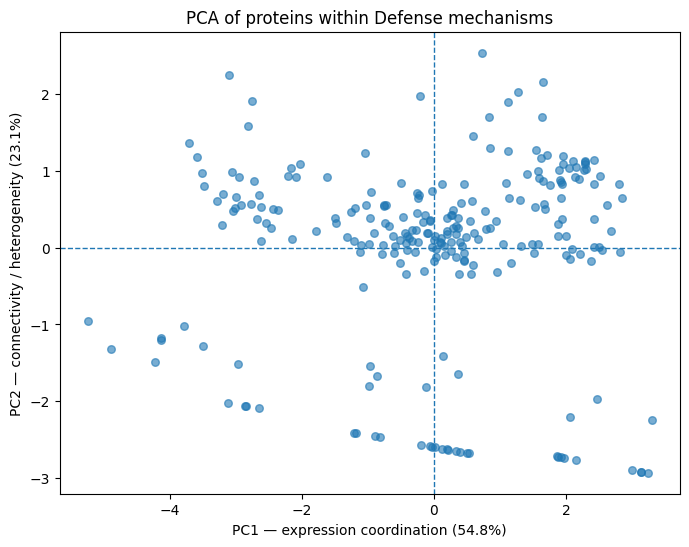

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(
    pca_df["PC1"],
    pca_df["PC2"],
    alpha=0.6,
    s=30
)

plt.axhline(0, linestyle="--", linewidth=1)
plt.axvline(0, linestyle="--", linewidth=1)

plt.xlabel("PC1 — expression coordination (54.8%)")
plt.ylabel("PC2 — connectivity / heterogeneity (23.1%)")

plt.title("PCA of proteins within Defense mechanisms")

plt.show()

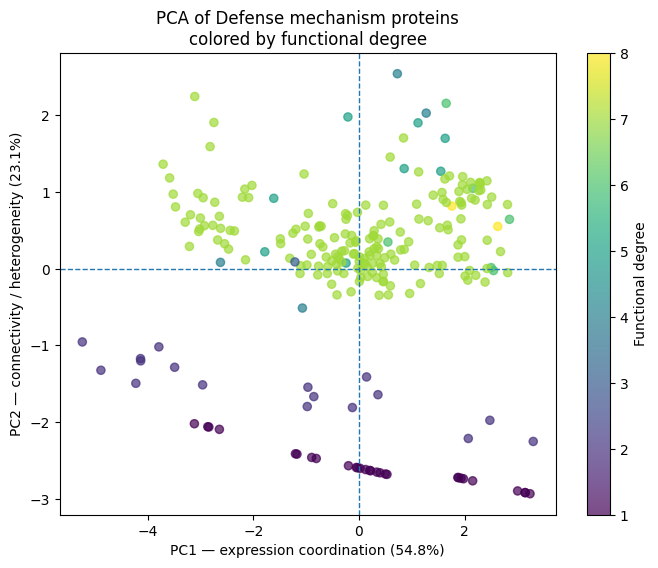

In [ ]:
plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    pca_df["PC1"],
    pca_df["PC2"],
    c=pca_df["function_degree"],
    s=35,
    alpha=0.7
)

plt.colorbar(
    scatter,
    label="Functional degree"
)

plt.axhline(0, linestyle="--", linewidth=1)
plt.axvline(0, linestyle="--", linewidth=1)

plt.xlabel("PC1 — expression coordination (54.8%)")
plt.ylabel("PC2 — connectivity / heterogeneity (23.1%)")

plt.title(
    "PCA of Defense mechanism proteins\ncolored by functional degree"
)

plt.show()

In [ ]:
expression_features = [
    "mean_spearman",
    "median_spearman",
    "sd_spearman",
    "fraction_positive",
    "fraction_negative"
]

X_expression = pca_df[expression_features]

scaler_expression = StandardScaler()
X_expression_scaled = scaler_expression.fit_transform(X_expression)

pca_expression = PCA(n_components=2)

X_expression_pca = pca_expression.fit_transform(
    X_expression_scaled
)

print(
    "PC1 explained variance:",
    round(pca_expression.explained_variance_ratio_[0], 3)
)

print(
    "PC2 explained variance:",
    round(pca_expression.explained_variance_ratio_[1], 3)
)

print(
    "Total explained variance:",
    round(pca_expression.explained_variance_ratio_.sum(), 3)
)

PC1 explained variance: 0.656
PC2 explained variance: 0.206
Total explained variance: 0.863


In [ ]:
expression_loadings = pd.DataFrame(
    pca_expression.components_.T,
    index=expression_features,
    columns=["PC1", "PC2"]
)

display(expression_loadings.round(3))

,PC1,PC2
mean_spearman,0.541,-0.126
median_spearman,0.544,-0.054
sd_spearman,0.148,0.897
fraction_positive,0.428,0.264
fraction_negative,-0.454,0.326


In [ ]:
# Add PCA coordinates to the existing dataframe

pca_df = pca_df.copy()

pca_df["PC1"] = X_pca[:, 0]
pca_df["PC2"] = X_pca[:, 1]

# Check
display(
    pca_df[
        ["protein", "function_degree", "PC1", "PC2"]
    ].head(10)
)

,protein,function_degree,PC1,PC2
0,b0041,1,-3.114135,-2.019451
1,b0066,7,0.603150,0.188049
2,b0067,7,2.059373,-0.150570
3,b0068,7,-0.138112,0.430512
4,b0128,1,1.931988,-2.728615
5,b0151,7,-0.370389,0.123044
6,b0152,7,-0.053111,0.362422
7,b0153,7,-0.619098,0.150062
8,b0158,7,0.368728,0.258452
9,b0196,1,0.530237,-2.678577


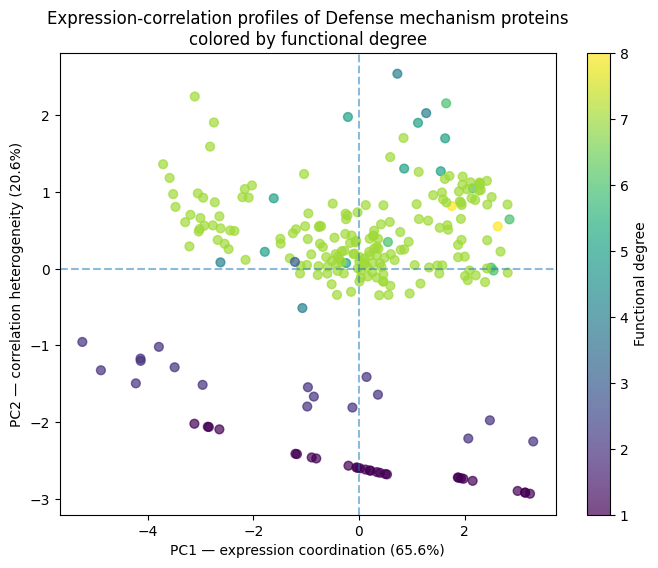

In [ ]:
plt.figure(figsize=(8, 6))

sc = plt.scatter(
    pca_df["PC1"],
    pca_df["PC2"],
    c=pca_df["function_degree"],
    s=40,
    alpha=0.7
)

plt.colorbar(sc, label="Functional degree")

plt.axhline(0, linestyle="--", alpha=0.5)
plt.axvline(0, linestyle="--", alpha=0.5)

plt.xlabel("PC1 — expression coordination (65.6%)")
plt.ylabel("PC2 — correlation heterogeneity (20.6%)")

plt.title(
    "Expression-correlation profiles of Defense mechanism proteins\n"
    "colored by functional degree"
)

plt.show()

In [ ]:
# Keep proteins with at least 2 Defense-mechanism partners
cluster_df = pca_df[
    pca_df["function_degree"] >= 2
].copy()

print("Proteins used for clustering:", len(cluster_df))

display(
    cluster_df[
        [
            "protein",
            "function_degree",
            "mean_spearman",
            "median_spearman",
            "sd_spearman",
            "fraction_positive",
            "fraction_negative",
            "PC1",
            "PC2"
        ]
    ].head(10)
)

Proteins used for clustering: 216


,protein,function_degree,mean_spearman,median_spearman,sd_spearman,fraction_positive,fraction_negative,PC1,PC2
1,b0066,7,0.387199,0.377384,0.108468,0.142857,0.000000,0.603150,0.188049
2,b0067,7,0.547503,0.552031,0.080100,0.857143,0.000000,2.059373,-0.150570
3,b0068,7,0.246640,0.194952,0.127327,0.000000,0.000000,-0.138112,0.430512
5,b0151,7,0.177595,0.182440,0.085037,0.000000,0.000000,-0.370389,0.123044
6,b0152,7,0.265943,0.228469,0.120504,0.000000,0.000000,-0.053111,0.362422
7,b0153,7,0.131187,0.094694,0.084102,0.000000,0.000000,-0.619098,0.150062
8,b0158,7,0.333535,0.299978,0.112872,0.142857,0.000000,0.368728,0.258452
10,b0197,7,0.086291,0.088901,0.121584,0.000000,0.285714,-1.018244,0.551514
11,b0198,7,0.261206,0.263958,0.037595,0.000000,0.000000,-0.149049,-0.302378
12,b0199,7,0.444800,0.451698,0.045898,0.000000,0.000000,0.556926,-0.342788


In [ ]:
# Features used for clustering
feature_cols = [
    "mean_spearman",
    "median_spearman",
    "sd_spearman",
    "fraction_positive",
    "fraction_negative"
]

# Data for the 216 proteins
X_cluster = cluster_df[feature_cols]

# Standardize again using only these 216 proteins
scaler_cluster = StandardScaler()
X_cluster_scaled = scaler_cluster.fit_transform(X_cluster)

# Test different numbers of clusters
silhouette_results = []

for k in range(2, 7):
    
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )
    
    labels = kmeans.fit_predict(X_cluster_scaled)
    
    score = silhouette_score(
        X_cluster_scaled,
        labels
    )
    
    silhouette_results.append({
        "k": k,
        "silhouette_score": score
    })

silhouette_df = pd.DataFrame(silhouette_results)

display(silhouette_df)

,k,silhouette_score
0,2,0.491228
1,3,0.539790
2,4,0.553833
3,5,0.426200
4,6,0.416440


In [ ]:
# K-means clustering with k = 4
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=20
)

cluster_df["cluster"] = kmeans.fit_predict(X_cluster_scaled)

# Check cluster sizes
print(cluster_df["cluster"].value_counts().sort_index())

cluster
0     60
1    105
2     41
3     10
Name: count, dtype: int64


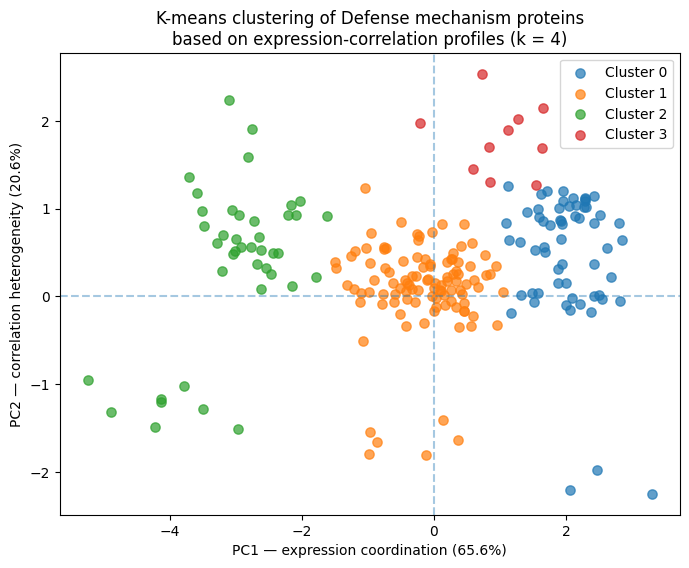

In [ ]:
plt.figure(figsize=(8, 6))

for cluster_id in sorted(cluster_df["cluster"].unique()):
    
    temp = cluster_df[
        cluster_df["cluster"] == cluster_id
    ]
    
    plt.scatter(
        temp["PC1"],
        temp["PC2"],
        s=45,
        alpha=0.7,
        label=f"Cluster {cluster_id}"
    )

plt.axhline(0, linestyle="--", alpha=0.4)
plt.axvline(0, linestyle="--", alpha=0.4)

plt.xlabel("PC1 — expression coordination (65.6%)")
plt.ylabel("PC2 — correlation heterogeneity (20.6%)")

plt.title(
    "K-means clustering of Defense mechanism proteins\n"
    "based on expression-correlation profiles (k = 4)"
)

plt.legend()
plt.show()

In [ ]:
cluster_summary = (
    cluster_df
    .groupby("cluster")
    .agg(
        n_proteins=("protein", "count"),
        mean_function_degree=("function_degree", "mean"),
        mean_spearman=("mean_spearman", "mean"),
        median_spearman=("median_spearman", "mean"),
        mean_sd_spearman=("sd_spearman", "mean"),
        mean_fraction_positive=("fraction_positive", "mean"),
        mean_fraction_negative=("fraction_negative", "mean")
    )
    .round(3)
)

display(cluster_summary)

,n_proteins,mean_function_degree,mean_spearman,median_spearman,mean_sd_spearman,mean_fraction_positive,mean_fraction_negative
cluster,,,,,,,
0,60,6.717,0.522,0.583,0.168,0.699,0.007
1,105,6.619,0.239,0.249,0.100,0.022,0.055
2,41,5.854,-0.209,-0.227,0.102,0.000,0.898
3,10,5.300,0.322,0.429,0.369,0.424,0.271


In [ ]:
# Add gene annotations to the clustering results

cluster_annotated_df = cluster_df.merge(
    gene_info_df[
        ["gene_id", "gene_name", "gene_product", "cog"]
    ],
    left_on="protein",
    right_on="gene_id",
    how="left"
)

# Sort by cluster and then by functional degree
cluster_annotated_df = cluster_annotated_df.sort_values(
    ["cluster", "function_degree"],
    ascending=[True, False]
)

display(
    cluster_annotated_df[
        [
            "cluster",
            "protein",
            "gene_name",
            "gene_product",
            "function_degree",
            "mean_spearman",
            "sd_spearman",
            "fraction_positive",
            "fraction_negative"
        ]
    ].head(30)
)

,cluster,protein,gene_name,gene_product,function_degree,mean_spearman,sd_spearman,fraction_positive,fraction_negative
58,0,b1116,lolC,lipoprotein release complex - inner membrane s...,8,0.500852,0.156510,0.625000,0.000000
60,0,b1118,lolE,lipoprotein release complex - inner membrane s...,8,0.646881,0.135308,0.875000,0.000000
1,0,b0067,thiP,thiamine ABC transporter membrane subunit,7,0.547503,0.080100,0.857143,0.000000
15,0,b0490,fetA,putative iron ABC exporter ATP-binding subunit...,7,0.397247,0.167904,0.428571,0.000000
25,0,b0760,modF,ABC family protein ModF,7,0.547554,0.095988,0.857143,0.000000
32,0,b0794,ybhF,ABC exporter ATP binding subunit YbhF,7,0.647204,0.212835,0.857143,0.000000
36,0,b0829,gsiA,glutathione ABC transporter ATP binding subuni...,7,0.482365,0.099623,0.571429,0.000000
39,0,b0832,gsiD,glutathione ABC transporter membrane subunit GsiD,7,0.460406,0.097790,0.571429,0.000000
42,0,b0856,potH,putrescine ABC transporter membrane subunit PotH,7,0.459925,0.164509,0.571429,0.000000
43,0,b0857,potI,putrescine ABC transporter membrane subunit PotI,7,0.471696,0.157804,0.571429,0.000000


In [ ]:
kmeans = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=20
)

labels = kmeans.fit_predict(X_cluster_scaled)

score = silhouette_score(
    X_cluster_scaled,
    labels
)
display(silhouette_df)

,k,silhouette_score
0,2,0.491228
1,3,0.539790
2,4,0.553833
3,5,0.426200
4,6,0.416440


In [ ]:
for cluster_id in range(4):
    
    print(f"\n===== CLUSTER {cluster_id} =====")
    
    display(
        cluster_annotated_df[
            cluster_annotated_df["cluster"] == cluster_id
        ][
            [
                "protein",
                "gene_name",
                "gene_product",
                "function_degree",
                "mean_spearman",
                "sd_spearman"
            ]
        ].head(20)
    )


===== CLUSTER 0 =====


,protein,gene_name,gene_product,function_degree,mean_spearman,sd_spearman
58,b1116,lolC,lipoprotein release complex - inner membrane s...,8,0.500852,0.156510
60,b1118,lolE,lipoprotein release complex - inner membrane s...,8,0.646881,0.135308
1,b0067,thiP,thiamine ABC transporter membrane subunit,7,0.547503,0.080100
15,b0490,fetA,putative iron ABC exporter ATP-binding subunit...,7,0.397247,0.167904
25,b0760,modF,ABC family protein ModF,7,0.547554,0.095988
32,b0794,ybhF,ABC exporter ATP binding subunit YbhF,7,0.647204,0.212835
36,b0829,gsiA,glutathione ABC transporter ATP binding subuni...,7,0.482365,0.099623
39,b0832,gsiD,glutathione ABC transporter membrane subunit GsiD,7,0.460406,0.097790
42,b0856,potH,putrescine ABC transporter membrane subunit PotH,7,0.459925,0.164509
43,b0857,potI,putrescine ABC transporter membrane subunit PotI,7,0.471696,0.157804



===== CLUSTER 1 =====


,protein,gene_name,gene_product,function_degree,mean_spearman,sd_spearman
0,b0066,thiQ,thiamine ABC transporter ATP binding subunit,7,0.387199,0.108468
2,b0068,thiB,thiamine ABC transporter periplasmic binding p...,7,0.246640,0.127327
3,b0151,fhuC,iron(III) hydroxamate ABC transporter ATP bind...,7,0.177595,0.085037
4,b0152,fhuD,iron(III) hydroxamate ABC transporter periplas...,7,0.265943,0.120504
5,b0153,fhuB,iron(III) hydroxamate ABC transporter membrane...,7,0.131187,0.084102
6,b0158,btuF,vitamin B12 ABC transporter periplasmic bindin...,7,0.333535,0.112872
7,b0197,metQ,L-methionine\/D-methionine ABC transporter mem...,7,0.086291,0.121584
8,b0198,metI,L-methionine\/D-methionine ABC transporter mem...,7,0.261206,0.037595
9,b0199,metN,L-methionine\/D-methionine ABC transporter ATP...,7,0.444800,0.045898
10,b0365,tauA,taurine ABC transporter periplasmic binding pr...,7,0.181407,0.065963



===== CLUSTER 2 =====


,protein,gene_name,gene_product,function_degree,mean_spearman,sd_spearman
44,b0860,artJ,L-arginine ABC transporter periplasmic binding...,7,-0.391178,0.161171
61,b1124,potC,spermidine preferential ABC transporter membra...,7,-0.196499,0.207957
62,b1125,potB,spermidine preferential ABC transporter membra...,7,-0.196473,0.247422
63,b1126,potA,spermidine preferential ABC transporter ATP bi...,7,-0.283724,0.282289
68,b1247,oppF,murein tripeptide ABC transporter\/oligopeptid...,7,-0.028890,0.042384
70,b1291,sapD,putrescine ABC exporter ATP binding protein SapD,7,-0.051534,0.162259
97,b1857,znuA,Zn(2(+)) ABC transporter periplasmic binding p...,7,-0.316900,0.097714
98,b1858,znuC,Zn(2(+)) ABC transporter ATP binding subunit,7,-0.169699,0.067392
108,b1920,tcyJ,cystine ABC transporter periplasmic binding pr...,7,-0.214049,0.040338
116,b2148,mglC,D-galactose\/methyl-galactoside ABC transporte...,7,-0.166482,0.089421



===== CLUSTER 3 =====


,protein,gene_name,gene_product,function_degree,mean_spearman,sd_spearman
151,b3035,tolC,outer membrane channel TolC,7,0.320801,0.286301
157,b3271,yhdZ,putative ABC transporter ATP-binding subunit YhdZ,7,0.304080,0.258648
50,b0878,macA,ABC-type tripartite efflux pump membrane fusio...,6,0.388001,0.389434
13,b0462,acrB,multidrug efflux pump RND permease AcrB,5,0.339112,0.396408
14,b0463,acrA,multidrug efflux pump membrane fusion lipoprot...,5,0.391783,0.323203
141,b2470,acrD,multidrug efflux pump RND permease AcrD,5,0.277650,0.318525
149,b2686,emrB,multidrug efflux pump membrane subunit EmrB,5,0.393026,0.376884
154,b3266,acrF,multidrug efflux pump RND permease AcrF,5,0.155615,0.385740
110,b2075,mdtB,multidrug efflux pump RND permease subunit MdtB,4,0.287599,0.501400
111,b2076,mdtC,multidrug efflux pump RND permease subunit MdtC,4,0.359773,0.452061


In [ ]:
# Given that a protein belongs to the broad Defense mechanisms COG category, 
# can network connectivity and expression-correlation patterns preliminary distinguish 
# finer functional submodules within this broad category?

# Leave-one-protein-out validation
# Step 1: Save the full-data clustering as reference

reference_df = cluster_df.copy()

reference_df = reference_df[
    [
        "protein",
        "mean_spearman",
        "median_spearman",
        "sd_spearman",
        "fraction_positive",
        "fraction_negative",
        "cluster"
    ]
].copy()

reference_df = reference_df.rename(
    columns={"cluster": "reference_cluster"}
)

print("Number of proteins:", len(reference_df))
display(reference_df.head(10))

Number of proteins: 216


,protein,mean_spearman,median_spearman,sd_spearman,fraction_positive,fraction_negative,reference_cluster
1,b0066,0.387199,0.377384,0.108468,0.142857,0.000000,1
2,b0067,0.547503,0.552031,0.080100,0.857143,0.000000,0
3,b0068,0.246640,0.194952,0.127327,0.000000,0.000000,1
5,b0151,0.177595,0.182440,0.085037,0.000000,0.000000,1
6,b0152,0.265943,0.228469,0.120504,0.000000,0.000000,1
7,b0153,0.131187,0.094694,0.084102,0.000000,0.000000,1
8,b0158,0.333535,0.299978,0.112872,0.142857,0.000000,1
10,b0197,0.086291,0.088901,0.121584,0.000000,0.285714,1
11,b0198,0.261206,0.263958,0.037595,0.000000,0.000000,1
12,b0199,0.444800,0.451698,0.045898,0.000000,0.000000,1


In [ ]:
# Step 2: Test leave-one-protein-out with one protein
test_protein = "b0462"

# The protein is treated as an unseen protein
test_df = reference_df[
    reference_df["protein"] == test_protein
].copy()

# All remaining proteins are used for training
train_df = reference_df[
    reference_df["protein"] != test_protein
].copy()

print("Test protein:")
display(test_df)
print("Number of training proteins:", len(train_df))

# Step 2.2: Fit scaler and PCA using training proteins only

feature_cols = [
    "mean_spearman",
    "median_spearman",
    "sd_spearman",
    "fraction_positive",
    "fraction_negative"
]

# Features from the 215 training proteins
X_train = train_df[feature_cols]

# Standardize using training proteins only
loo_scaler = StandardScaler()

X_train_scaled = loo_scaler.fit_transform(X_train)

# Fit PCA using training proteins only
loo_pca = PCA(n_components=2)

X_train_pca = loo_pca.fit_transform(X_train_scaled)

print("Training proteins:", len(train_df))
print("PCA shape:", X_train_pca.shape)

print(
    "PC1 explained variance:",
    round(loo_pca.explained_variance_ratio_[0], 3)
)

print(
    "PC2 explained variance:",
    round(loo_pca.explained_variance_ratio_[1], 3)
)

print(
    "Total explained variance:",
    round(loo_pca.explained_variance_ratio_.sum(), 3)
)

# Step 2.3: Project the unseen protein into the PCA space
# Extract features of the unseen protein
X_test = test_df[feature_cols]

# IMPORTANT:
# Only transform — do NOT fit again
X_test_scaled = loo_scaler.transform(X_test)

# Project the unseen protein into the PCA space
X_test_pca = loo_pca.transform(X_test_scaled)

print()
print("Unseen protein:", test_protein)
print("PC1:", round(X_test_pca[0, 0], 3))
print("PC2:", round(X_test_pca[0, 1], 3))

# Step 2.4: Train K-means on the 215 known proteins
# and predict the unseen protein
# Train K-means using only the 215 training proteins
loo_kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=20
)

train_clusters = loo_kmeans.fit_predict(X_train_scaled)

# Predict cluster for unseen protein
predicted_cluster = loo_kmeans.predict(X_test_scaled)[0]

print()
print("Unseen protein:", test_protein)
print("Predicted cluster:", predicted_cluster)

train_result_df = train_df.copy()
train_result_df["loo_cluster"] = train_clusters

print()
print(
    train_result_df["loo_cluster"]
    .value_counts()
    .sort_index()
)


Test protein:


,protein,mean_spearman,median_spearman,sd_spearman,fraction_positive,fraction_negative,reference_cluster
18,b0462,0.339112,0.415133,0.396408,0.4,0.2,3


Number of training proteins: 215
Training proteins: 215
PCA shape: (215, 2)
PC1 explained variance: 0.68
PC2 explained variance: 0.204
Total explained variance: 0.884

Unseen protein: b0462
PC1: 1.519
PC2: 2.851

Unseen protein: b0462
Predicted cluster: 3

loo_cluster
0    105
1     41
2     60
3      9
Name: count, dtype: int64


In [ ]:
predicted_submodule_df = train_result_df[
    train_result_df["loo_cluster"] == predicted_cluster
].copy()

print(
    "Number of known proteins in predicted submodule:",
    len(predicted_submodule_df)
)

display(
    predicted_submodule_df[
        [
            "protein",
            "mean_spearman",
            "median_spearman",
            "sd_spearman",
            "fraction_positive",
            "fraction_negative"
        ]
    ].head(20)
    
)

predicted_submodule_annotated = predicted_submodule_df.merge(
    gene_info_df[
        ["gene_id", "gene_name", "gene_product"]
    ],
    left_on="protein",
    right_on="gene_id",
    how="left"
)

display(
    predicted_submodule_annotated[
        [
            "protein",
            "gene_name",
            "gene_product",
            "mean_spearman",
            "sd_spearman"
        ]
    ].head(30)
)

Number of known proteins in predicted submodule: 9


,protein,mean_spearman,median_spearman,sd_spearman,fraction_positive,fraction_negative
19,b0463,0.391783,0.534158,0.323203,0.600000,0.200000
61,b0878,0.388001,0.566351,0.389434,0.666667,0.333333
128,b2075,0.287599,0.305910,0.501400,0.500000,0.500000
129,b2076,0.359773,0.401851,0.452061,0.500000,0.250000
159,b2470,0.277650,0.413807,0.318525,0.400000,0.200000
167,b2686,0.393026,0.524775,0.376884,0.600000,0.200000
169,b3035,0.320801,0.411757,0.286301,0.428571,0.285714
174,b3266,0.155615,0.304384,0.385740,0.000000,0.400000
177,b3271,0.304080,0.411106,0.258648,0.142857,0.142857


,protein,gene_name,gene_product,mean_spearman,sd_spearman
0,b0463,acrA,multidrug efflux pump membrane fusion lipoprot...,0.391783,0.323203
1,b0878,macA,ABC-type tripartite efflux pump membrane fusio...,0.388001,0.389434
2,b2075,mdtB,multidrug efflux pump RND permease subunit MdtB,0.287599,0.501400
3,b2076,mdtC,multidrug efflux pump RND permease subunit MdtC,0.359773,0.452061
4,b2470,acrD,multidrug efflux pump RND permease AcrD,0.277650,0.318525
5,b2686,emrB,multidrug efflux pump membrane subunit EmrB,0.393026,0.376884
6,b3035,tolC,outer membrane channel TolC,0.320801,0.286301
7,b3266,acrF,multidrug efflux pump RND permease AcrF,0.155615,0.385740
8,b3271,yhdZ,putative ABC transporter ATP-binding subunit YhdZ,0.304080,0.258648


In [ ]:
# Step 3: Leave-one-protein-out analysis for all proteins

def match_cluster_labels(reference_labels, new_labels, n_clusters=4):
    """
    Match newly generated K-means cluster labels to the
    original reference cluster labels.

    K-means cluster numbers are arbitrary, so the Hungarian
    algorithm is used to maximize agreement between clusters.
    """

    # Build overlap matrix
    overlap_matrix = np.zeros(
        (n_clusters, n_clusters),
        dtype=int
    )

    for ref_label, new_label in zip(reference_labels, new_labels):
        overlap_matrix[ref_label, new_label] += 1

    # Find the mapping that maximizes overlap
    row_ind, col_ind = linear_sum_assignment(-overlap_matrix)

    # Map: new cluster -> reference cluster
    label_mapping = {
        new_label: ref_label
        for ref_label, new_label in zip(row_ind, col_ind)
    }

    return label_mapping

In [ ]:
# Run leave-one-protein-out prediction for all 216 proteins

loo_results = []

for held_out_idx in reference_df.index:

    # --------------------------------------------------------
    # 1. Split into training proteins and one held-out protein

    train_df = reference_df.drop(index=held_out_idx).copy()
    test_df = reference_df.loc[[held_out_idx]].copy()

    X_train = train_df[feature_cols]
    X_test = test_df[feature_cols]

    # --------------------------------------------------------
    # 2. Standardize using training proteins only

    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    # --------------------------------------------------------
    # 3. Fit PCA using training proteins only

    pca = PCA(n_components=2)

    X_train_pca = pca.fit_transform(X_train_scaled)
    X_test_pca = pca.transform(X_test_scaled)

    # --------------------------------------------------------
    # 4. Fit K-means using training proteins only

    kmeans = KMeans(
        n_clusters=4,
        random_state=42,
        n_init=20
    )

    train_new_labels = kmeans.fit_predict(X_train_scaled)

    # Predict the held-out protein
    test_new_label = kmeans.predict(X_test_scaled)[0]

    # --------------------------------------------------------
    # 5. Match new cluster labels to reference cluster labels

    label_mapping = match_cluster_labels(
        reference_labels=train_df["reference_cluster"].to_numpy(),
        new_labels=train_new_labels,
        n_clusters=4
    )

    predicted_reference_cluster = label_mapping[test_new_label]

    # --------------------------------------------------------
    # 6. Save result

    loo_results.append({
        "protein": test_df["protein"].iloc[0],
        "reference_cluster": test_df["reference_cluster"].iloc[0],
        "predicted_cluster": predicted_reference_cluster,
        "match": (
            test_df["reference_cluster"].iloc[0]
            == predicted_reference_cluster
        ),
        "PC1": X_test_pca[0, 0],
        "PC2": X_test_pca[0, 1]
    })



In [ ]:
loo_results_df = pd.DataFrame(loo_results)

print("Number of proteins tested:", len(loo_results_df))
display(loo_results_df.head(30))

    # Count matched and unmatched proteins
n_true = loo_results_df["match"].sum()
n_false = (~loo_results_df["match"]).sum()

print("\nLOPO prediction summary:")
print("True :", n_true)
print("False:", n_false)

Number of proteins tested: 216


,protein,reference_cluster,predicted_cluster,match,PC1,PC2
0,b0066,1,1,True,0.594382,-0.711916
1,b0067,0,0,True,2.084657,-0.416655
2,b0068,1,1,True,-0.136194,-0.524449
3,b0151,1,1,True,-0.414914,-0.917363
4,b0152,1,1,True,-0.059282,-0.615755
5,b0153,1,1,True,-0.663027,-0.873848
6,b0158,1,1,True,0.365864,-0.612351
7,b0197,1,1,True,-1.016844,-0.100796
8,b0198,1,1,True,-0.248573,-1.482320
9,b0199,1,1,True,0.462952,-1.555919



LOPO prediction summary:
True : 216
False: 0


In [ ]:
# Define the five clustering features
feature_cols = [
    "mean_spearman",
    "median_spearman",
    "sd_spearman",
    "fraction_positive",
    "fraction_negative"
]

X = reference_df[feature_cols].to_numpy()
reference_labels = reference_df["reference_cluster"].to_numpy()

loo_results = []

# Leave one protein out at a time
for i in range(len(reference_df)):

    train_mask = np.arange(len(reference_df)) != i

    X_train = X[train_mask]
    X_test = X[~train_mask]

    # Fit the scaler using training proteins only
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    # Refit K-means using training proteins only
    model = KMeans(
        n_clusters=4,
        random_state=42,
        n_init=20
    )

    train_labels = model.fit_predict(X_train_scaled)

    # Align cluster labels with the full-data reference
    contingency = pd.crosstab(
        train_labels,
        reference_labels[train_mask]
    ).reindex(
        index=range(4),
        columns=range(4),
        fill_value=0
    )

    rows, cols = linear_sum_assignment(
        -contingency.to_numpy()
    )

    label_mapping = dict(zip(rows, cols))

    # Predict the held-out protein's cluster
    predicted_raw = model.predict(X_test_scaled)[0]
    predicted_cluster = label_mapping[predicted_raw]

    loo_results.append({
        "protein": reference_df.iloc[i]["protein"],
        "reference_cluster": reference_labels[i],
        "predicted_cluster": predicted_cluster,
        "correct": predicted_cluster == reference_labels[i]
    })

loo_df = pd.DataFrame(loo_results)

# Evaluate agreement with the reference clustering
agreement = loo_df["correct"].mean()

print("Number of proteins:", len(loo_df))
print(f"Leave-one-out cluster agreement: {agreement:.3f}")

display(
    pd.crosstab(
        loo_df["reference_cluster"],
        loo_df["predicted_cluster"],
        rownames=["Reference cluster"],
        colnames=["Predicted cluster"]
    )
)

Number of proteins: 216
Leave-one-out cluster agreement: 1.000


Predicted cluster,0,1,2,3
Reference cluster,,,,
0,60,0,0,0
1,0,105,0,0
2,0,0,41,0
3,0,0,0,10


In [ ]:
# Select the same five correlation features
feature_cols = [
    "mean_spearman",
    "median_spearman",
    "sd_spearman",
    "fraction_positive",
    "fraction_negative"
]

X = reference_df[feature_cols].to_numpy()
reference_labels = reference_df["reference_cluster"].to_numpy()

# Define 5-fold cross-validation
kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for fold, (train_idx, test_idx) in enumerate(kf.split(X), start=1):

    X_train = X[train_idx]
    X_test = X[test_idx]

    # Fit scaling on training data only
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    # Fit K-means on training data only
    model = KMeans(
        n_clusters=4,
        random_state=42,
        n_init=20
    )

    train_labels = model.fit_predict(X_train_scaled)

    # Match K-means labels to reference labels
    contingency = pd.crosstab(
        train_labels,
        reference_labels[train_idx]
    ).reindex(
        index=range(4),
        columns=range(4),
        fill_value=0
    )

    rows, cols = linear_sum_assignment(
        -contingency.to_numpy()
    )

    mapping = dict(zip(rows, cols))

    # Predict held-out proteins
    test_predictions = model.predict(X_test_scaled)

    for idx, prediction in zip(test_idx, test_predictions):
        predicted_cluster = mapping[prediction]

        cv_results.append({
            "protein": reference_df.iloc[idx]["protein"],
            "fold": fold,
            "reference_cluster": reference_labels[idx],
            "predicted_cluster": predicted_cluster,
            "correct": predicted_cluster == reference_labels[idx]
        })

cv_df = pd.DataFrame(cv_results)

# Summarize cross-validation results
fold_summary = (
    cv_df.groupby("fold")
    .agg(
        n_test=("correct", "size"),
        agreement=("correct", "mean")
    )
    .reset_index()
)

print("5-fold cross-validation results:")
display(fold_summary)

print(
    "Overall agreement:",
    round(cv_df["correct"].mean(), 3)
)

print("\nConfusion matrix:")
display(
    pd.crosstab(
        cv_df["reference_cluster"],
        cv_df["predicted_cluster"],
        rownames=["Reference"],
        colnames=["Predicted"]
    )
)

5-fold cross-validation results:


,fold,n_test,agreement
0,1,44,1.0
1,2,43,1.0
2,3,43,1.0
3,4,43,1.0
4,5,43,1.0


Overall agreement: 1.0

Confusion matrix:


Predicted,0,1,2,3
Reference,,,,
0,60,0,0,0
1,0,105,0,0
2,0,0,41,0
3,0,0,0,10


In [ ]:
feature_cols = [
    "mean_spearman",
    "median_spearman",
    "sd_spearman",
    "fraction_positive",
    "fraction_negative"
]

X = reference_df[feature_cols].to_numpy()

kf = KFold(n_splits=5, shuffle=True, random_state=42)

margin_results = []

for fold, (train_idx, test_idx) in enumerate(kf.split(X), start=1):

    # Fit preprocessing on training data only
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X[train_idx])
    X_test = scaler.transform(X[test_idx])

    # Train the clustering model
    model = KMeans(
        n_clusters=4,
        random_state=42,
        n_init=20
    )
    model.fit(X_train)

    # Calculate distances to all cluster centers
    distances = model.transform(X_test)

    sorted_distances = np.sort(distances, axis=1)

    nearest = sorted_distances[:, 0]
    second_nearest = sorted_distances[:, 1]

    # Relative margin allows comparison across proteins
    relative_margin = (
        (second_nearest - nearest)
        / np.maximum(second_nearest, 1e-12)
    )

    for idx, margin in zip(test_idx, relative_margin):
        margin_results.append({
            "protein": reference_df.iloc[idx]["protein"],
            "fold": fold,
            "relative_margin": margin
        })

margin_df = pd.DataFrame(margin_results)

print("Mean relative margin:",
      round(margin_df["relative_margin"].mean(), 3))

print("Median relative margin:",
      round(margin_df["relative_margin"].median(), 3))

print("\nRelative margin distribution:")
display(margin_df["relative_margin"].describe())

print("\n10 proteins closest to cluster boundaries:")
display(margin_df.nsmallest(10, "relative_margin"))

Mean relative margin: 0.648
Median relative margin: 0.695

Relative margin distribution:


count    216.000000
mean       0.648052
std        0.194483
min        0.022792
25%        0.570893
50%        0.694884
75%        0.786683
max        0.941488
Name: relative_margin, dtype: float64


10 proteins closest to cluster boundaries:


,protein,fold,relative_margin
202,b3271,5,0.022792
5,b0792,1,0.081532
42,b4287,1,0.081795
66,b1487,2,0.110819
52,b0811,2,0.127577
104,b1516,3,0.135063
3,b0589,1,0.135598
199,b2367,5,0.135747
190,b1859,5,0.174328
177,b0830,5,0.195836
